Q1, h = 0.1
 x_n  y1_numeric   y1_exact      |err_y1|  y2_numeric   y2_exact      |err_y2|
   0           2          2             0           0          0             0
 0.1    1.645675  1.6456556 1.9361282e-05       0.164  0.1640192 1.9197354e-05
 0.2   1.3675711  1.3675424  2.871364e-05   0.2698907 0.26991912 2.8416984e-05
 0.3   1.1474198  1.1473879 3.1944288e-05  0.33421702 0.33424856 3.1541649e-05
 0.4  0.97154586 0.97151426 3.1597649e-05  0.36909472 0.36912583 3.1111886e-05
 0.5  0.82969013 0.82966082 2.9310317e-05  0.38337174  0.3834005 2.8760896e-05
 0.6  0.71413664 0.71411052 2.6110746e-05  0.38348723 0.38351275 2.5514181e-05
 0.7  0.61906436 0.61904173 2.2624571e-05  0.37410688 0.37412888 2.1994811e-05
 0.8  0.54006613 0.54004692 1.9214349e-05  0.35859245 0.35861101 1.8563115e-05
 0.9  0.47379125 0.47377517 1.6073921e-05  0.33934874 0.33936415 1.5411002e-05
   1   0.4176798 0.41766651 1.3291523e-05  0.31807975 0.31809237 1.2625041e-05


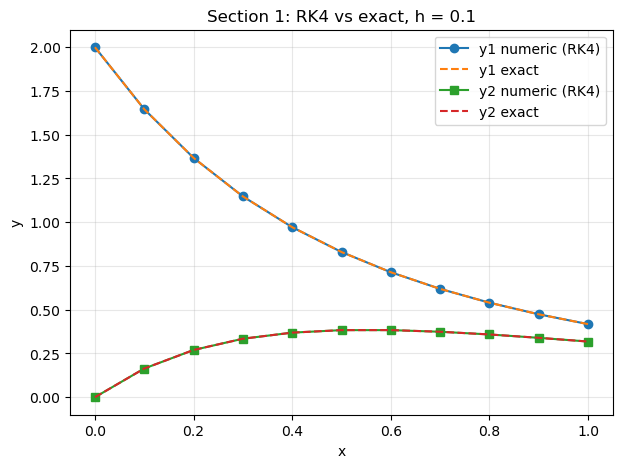

Q1, h = 0.05
 x_n  y1_numeric   y1_exact      |err_y1|  y2_numeric    y2_exact      |err_y2|
   0           2          2             0           0           0             0
0.05    1.811938  1.8119374 6.1990756e-07 0.090520833 0.090521448 6.1474232e-07
 0.1   1.6456567  1.6456556 1.0675867e-06  0.16401814   0.1640192 1.0577601e-06
0.15   1.4983375  1.4983361 1.3789882e-06  0.22307846  0.22307982 1.3649671e-06
 0.2    1.367544  1.3675424 1.5833883e-06  0.26991755  0.26991912 1.5656052e-06
0.25    1.251169  1.2511673 1.7045503e-06  0.30643255  0.30643423 1.6834056e-06
 0.3   1.1473896  1.1473879 1.7616931e-06  0.33424682  0.33424856  1.737557e-06
0.35   1.0546276  1.0546258 1.7702957e-06   0.3547486  0.35475034 1.7435102e-06
 0.4    0.971516 0.97151426 1.7427663e-06  0.36912412  0.36912583 1.7136472e-06
0.45   0.8968701 0.89686841 1.6889977e-06  0.37838623  0.37838789 1.6578365e-06
 0.5  0.82966244 0.82966082 1.6168275e-06  0.38339892   0.3834005 1.5838924e-06
0.55  0.76900125 0.76899972

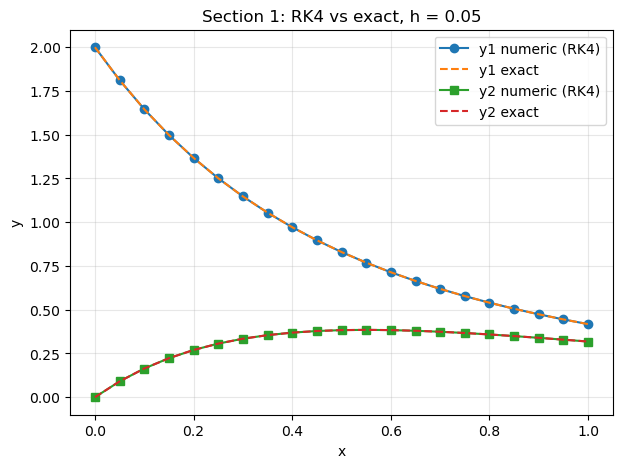


Max error at h=0.1   : 3.194e-05
Max error at h=0.05  : 1.770e-06
Error ratio (h -> h/2): 18.04  (expect ~16 for a 4th-order method)


In [ ]:
# Q1

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def save_op(n):
    text_path = Path(f"Q{n}.txt")
    text_path.write_text("", encoding="utf-8")
    plt_n = 0

    def print_r(*args, **kwargs):
        print(*args, **kwargs)
        with text_path.open("a", encoding="utf-8") as output:
            print(*args, file=output, **kwargs)

    def show_plt():
        nonlocal plt_n
        plt_n += 1
        path = Path(f"Q{n}_plot_{plt_n:02d}.png")
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return print_r, show_plt

print_r, show_plt = save_op(1)


def print_table(frame):
    print_r(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def rk4_system(f, y0, x0, xf, h):
    y0 = np.atleast_1d(np.asarray(y0, dtype=float))
    n_eq = y0.size
    N = int(round((xf - x0)/h))
    x = x0 + h * np.arange(N + 1)
    Y = np.zeros((N + 1, n_eq))
    Y[0] = y0
    for n in range(N):
        xn, yn = x[n], Y[n]
        k1 = f(xn, yn)
        k2 = f(xn + h/2, yn + h/2 * k1)
        k3 = f(xn + h/2, yn + h/2 * k2)
        k4 = f(xn + h, yn + h * k3)
        Y[n + 1] = yn + (h/6) * (k1 + 2 * k2 + 2 * k3 + k4)
    return x, Y


def f(x, y):
    y1, y2 = y
    return np.array([-2 * y1 + y2, y1 - 2 * y2])

def exact(x):
    y1e = np.exp(-x) + np.exp(-3 * x)
    y2e = np.exp(-x) - np.exp(-3 * x)
    return y1e, y2e

y0 = [2.0, 0.0]
results = {}
for h in (0.1, 0.05):
    x, Y = rk4_system(f, y0, 0.0, 1.0, h)
    y1e, y2e = exact(x)
    err1 = np.abs(Y[:, 0] - y1e)
    err2 = np.abs(Y[:, 1] - y2e)
    results[h] = (x, Y, y1e, y2e, err1, err2)

    df = pd.DataFrame({
        "x_n": x,
        "y1_numeric": Y[:, 0],
        "y1_exact": y1e,
        "|err_y1|": err1,
        "y2_numeric": Y[:, 1],
        "y2_exact": y2e,
        "|err_y2|": err2,
    })
    print_r(f"Q1, h = {h}")
    print_table(df)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(x, Y[:, 0], "o-", label="y1 numeric (RK4)")
    ax.plot(x, y1e, "--", label="y1 exact")
    ax.plot(x, Y[:, 1], "s-", label="y2 numeric (RK4)")
    ax.plot(x, y2e, "--", label="y2 exact")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Section 1: RK4 vs exact, h = {h}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    show_plt()

max_err_01 = max(results[0.1][4].max(), results[0.1][5].max())
max_err_005 = max(results[0.05][4].max(), results[0.05][5].max())
ratio = max_err_01/max_err_005 if max_err_005 > 0 else np.nan
print_r(f"\nMax error at h=0.1   : {max_err_01:.3e}")
print_r(f"Max error at h=0.05  : {max_err_005:.3e}")
print_r(f"Error ratio (h -> h/2): {ratio:.2f}  (expect ~16 for a 4th-order method)")

Q2, h = 0.1
 x_n    y_numeric  yprime_numeric      y_exact       |error|
   0            1               0            1             0
 0.1    0.9766875     -0.44941667   0.97668263  4.866043e-06
 0.2    0.9135234     -0.79708915   0.91351535 8.0570196e-06
 0.3   0.82058186      -1.0457696   0.82057238 9.4829685e-06
 0.4   0.70745479      -1.2021787   0.70744556 9.2322728e-06
 0.5   0.58290642      -1.2759833   0.58289889 7.5279561e-06
 0.6   0.45462778      -1.2788255    0.4546231 4.6837789e-06
 0.7   0.32908418        -1.22344   0.32908311 1.0629497e-06
 0.8   0.21144554      -1.1228807   0.21144849 2.9584519e-06
 0.9   0.10558795     -0.98987419   0.10559497 7.0219388e-06
   1  0.014153239     -0.83630435  0.014164049 1.0810208e-05
 1.1 -0.061346531     -0.67282906 -0.061332468 1.4063664e-05
 1.2  -0.12039251     -0.50862134  -0.12037592 1.6590142e-05
 1.3  -0.16330244     -0.35122454  -0.16328417 1.8268459e-05
 1.4  -0.19106468     -0.20650732  -0.19104564 1.9046683e-05
 1.5  -0.205

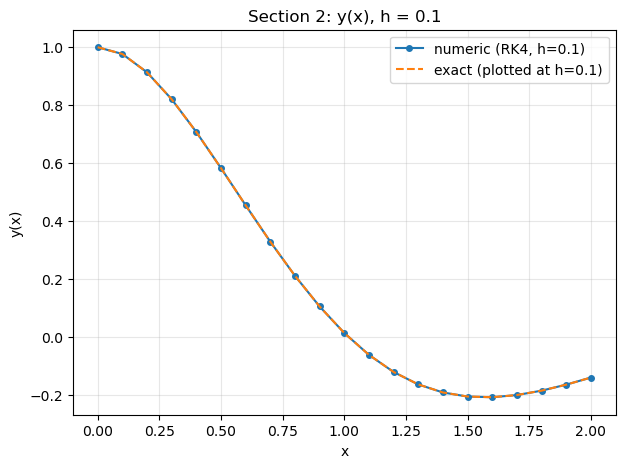

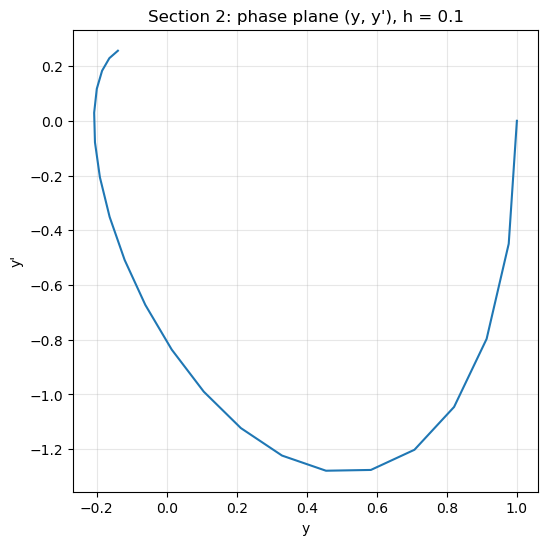

h=0.1: max |error| = 1.905e-05, max |y_numeric| = 1.000e+00
Q2, h = 0.4
 x_n   y_numeric  yprime_numeric     y_exact      |error|
   0           1               0           1            0
 0.4       0.712      -1.2106667  0.70744556 0.0045544426
 0.8  0.21380124      -1.1377038  0.21144849 0.0023527497
 1.2 -0.12324953     -0.51793512 -0.12037592 0.0028736139
 1.6 -0.21316303     0.031263009 -0.20744501  0.005718018
   2 -0.14420226        0.265189 -0.13967208 0.0045301729


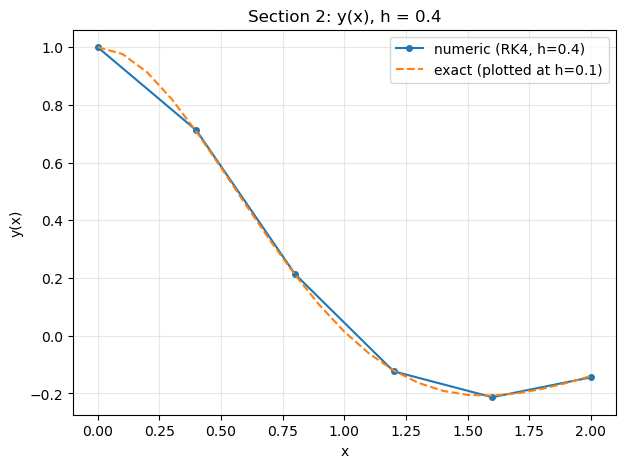

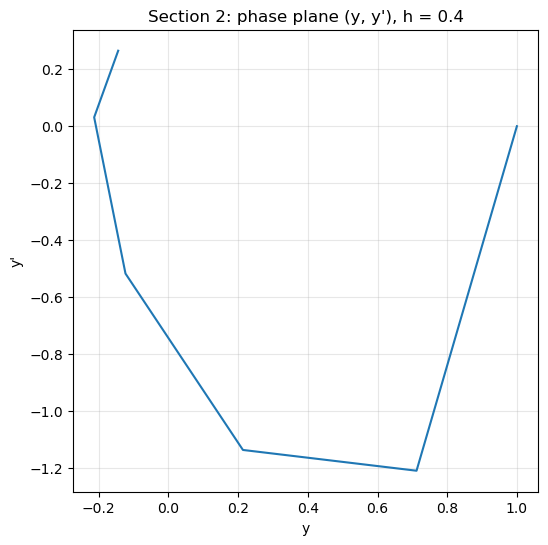

h=0.4: max |error| = 5.718e-03, max |y_numeric| = 1.000e+00


In [ ]:
# Q2

print_r, show_plt = save_op(2)


def print_table(frame):
    print_r(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}")) 


def f(x, y):
    y1, y2 = y
    return np.array([y2, -2 * y2 - 5 * y1])

def exact(x):
    return np.exp(-x) * (np.cos(2 * x) + 0.5 * np.sin(2 * x))

y0 = [1.0, 0.0]

h_exact_plot = 0.1
x_fine = np.arange(0.0, 2.0 + h_exact_plot/2, h_exact_plot)
ye_fine = exact(x_fine)

for h in (0.1, 0.4):
    x, Y = rk4_system(f, y0, 0.0, 2.0, h)
    ye = exact(x)
    err = np.abs(Y[:, 0] - ye)

    df = pd.DataFrame({
        "x_n": x, "y_numeric": Y[:, 0], "yprime_numeric": Y[:, 1],
        "y_exact": ye, "|error|": err,
    })
    print_r(f"Q2, h = {h}")
    print_table(df)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(x, Y[:, 0], "o-", ms=4, label=f"numeric (RK4, h={h})")
    ax.plot(x_fine, ye_fine, "--", label=f"exact (plotted at h={h_exact_plot})")
    ax.set_xlabel("x"); ax.set_ylabel("y(x)")
    ax.set_title(f"Section 2: y(x), h = {h}")
    ax.legend(); ax.grid(True, alpha=0.3)
    show_plt()

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(Y[:, 0], Y[:, 1])
    ax.set_xlabel("y"); ax.set_ylabel("y'")
    ax.set_title(f"Section 2: phase plane (y, y'), h = {h}")
    ax.grid(True, alpha=0.3)
    show_plt()

    print_r(f"h={h}: max |error| = {err.max():.3e}, "
          f"max |y_numeric| = {np.max(np.abs(Y[:,0])):.3e}")

Q3 summary, every 20th mesh point
 x_n     y1_RK4      y2_RK4    |V-V0|_RK4    y1_Heun     y2_Heun  |V-V0|_Heun
   0         10           5             0         10           5            0
   1 0.21860151   1.3766508 0.00080158558 0.23487338   1.3897177   0.20102152
   2 0.61213617 0.097264921 0.00080986241 0.65286799  0.10140901   0.21177985
   3  2.6317591 0.019199917 0.00081231988  2.7958418 0.021880208    0.2115064
   4  11.038197  0.37596017 0.00060791384  11.416807   0.5707954    0.1546583
   5 0.26420764   3.1329717 0.00082162297 0.27359186    2.788579   0.26586166
   6 0.40918247  0.20418088 0.00081876048 0.47342351  0.18968275   0.27808328
   7  1.6965844 0.024861199 0.00082295063  1.9669157 0.026721203   0.28040416
   8   7.410889 0.060204022   0.000821869  8.4852259  0.11630421   0.26421827
   9 0.69668821   6.7636634 0.00083136466 0.48779219   5.1795088   0.32425478
  10  0.2873792  0.44945951 0.00082686336 0.36192401  0.34956673   0.34104289
  11  1.0969992 0.040283866  0

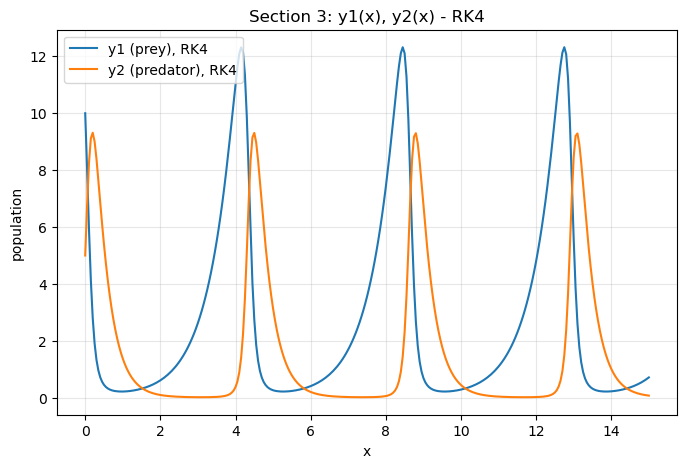

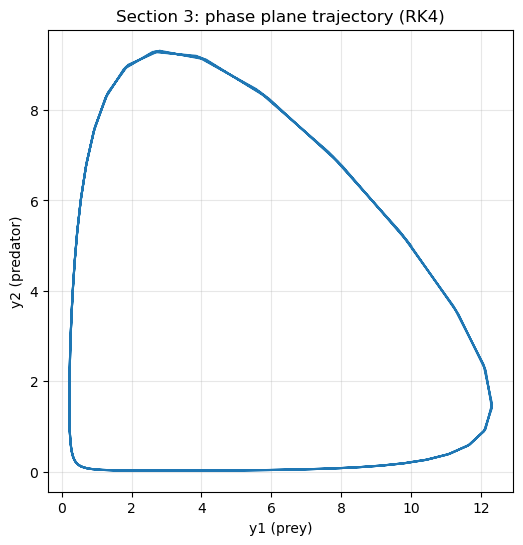

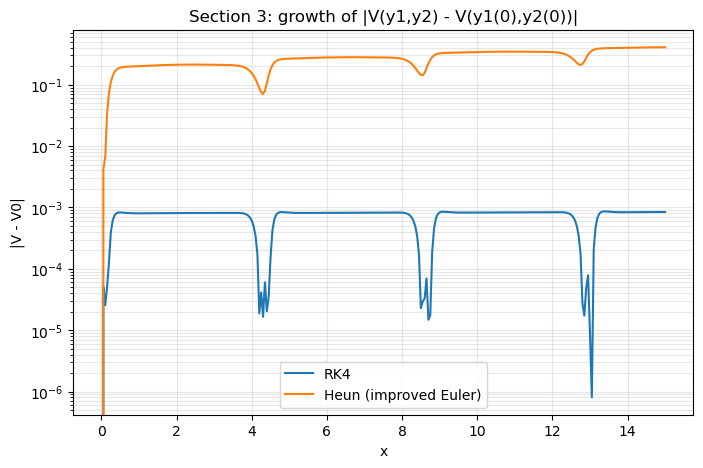

Final |V-V0| at x=15:  RK4 = 8.440e-04,  Heun = 4.084e-01


In [ ]:
# Q3

print_r, show_plt = save_op(3)


def print_table(frame):
    print_r(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))

def heun_system(f, y0, x0, xf, h):
    y0 = np.atleast_1d(np.asarray(y0, dtype=float))
    n_eq = y0.size
    N = int(round((xf - x0)/h))
    x = x0 + h * np.arange(N + 1)
    Y = np.zeros((N + 1, n_eq))
    Y[0] = y0
    for n in range(N):
        xn, yn = x[n], Y[n]
        k1 = f(xn, yn)
        y_pred = yn + h * k1
        k2 = f(xn + h, y_pred)
        Y[n + 1] = yn + (h/2) * (k1 + k2)
    return x, Y


a, b, c, d = 1.5, 1.0, 3.0, 1.0

def f(x, y):
    y1, y2 = y
    return np.array([a * y1 - b * y1 * y2, -c * y2 + d * y1 * y2])

def V(y1, y2):
    return d * y1 - c * np.log(y1) + b * y2 - a * np.log(y2)

y0 = [10.0, 5.0]
h = 0.05
V0 = V(*y0)

x_rk4, Y_rk4 = rk4_system(f, y0, 0.0, 15.0, h)
x_heun, Y_heun = heun_system(f, y0, 0.0, 15.0, h)

V_rk4 = V(Y_rk4[:, 0], Y_rk4[:, 1])
V_heun = V(Y_heun[:, 0], Y_heun[:, 1])
dV_rk4 = np.abs(V_rk4 - V0)
dV_heun = np.abs(V_heun - V0)

df = pd.DataFrame({
    "x_n": x_rk4,
    "y1_RK4": Y_rk4[:, 0], "y2_RK4": Y_rk4[:, 1], "|V-V0|_RK4": dV_rk4,
    "y1_Heun": Y_heun[:, 0], "y2_Heun": Y_heun[:, 1], "|V-V0|_Heun": dV_heun,
})
print_r("Q3 summary, every 20th mesh point")
print_table(df.iloc[::20])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_rk4, Y_rk4[:, 0], label="y1 (prey), RK4")
ax.plot(x_rk4, Y_rk4[:, 1], label="y2 (predator), RK4")
ax.set_xlabel("x"); ax.set_ylabel("population")
ax.set_title("Section 3: y1(x), y2(x) - RK4")
ax.legend(); ax.grid(True, alpha=0.3)
show_plt()

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(Y_rk4[:, 0], Y_rk4[:, 1])
ax.set_xlabel("y1 (prey)"); ax.set_ylabel("y2 (predator)")
ax.set_title("Section 3: phase plane trajectory (RK4)")
ax.grid(True, alpha=0.3)
show_plt()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_rk4, dV_rk4, label="RK4")
ax.plot(x_heun, dV_heun, label="Heun (improved Euler)")
ax.set_xlabel("x"); ax.set_ylabel("|V - V0|")
ax.set_yscale("log")
ax.set_title("Section 3: growth of |V(y1,y2) - V(y1(0),y2(0))|")
ax.legend(); ax.grid(True, alpha=0.3, which="both")
show_plt()

print_r(f"Final |V-V0| at x=15:  RK4 = {dV_rk4[-1]:.3e},  Heun = {dV_heun[-1]:.3e}")

Q4a milne tan
 x_n  y_predicted  y_corrected  corrector_iters  Milne_error_estimate  actual_error
   0          NaN            0                0                     0             0
 0.1          NaN   0.10033459                0                     0 8.3007286e-08
 0.2          NaN   0.20270988                0                     0 1.5727695e-07
 0.3          NaN   0.30933604                0                     0 2.1026465e-07
 0.4   0.42272271   0.42279666                5        -2.5499508e-06 3.4412037e-06
 0.5    0.5462023   0.54630836                6        -3.6572872e-06 5.8719695e-06
 0.6   0.68398004   0.68415102                6        -5.8960547e-06 1.4216436e-05
 0.7   0.84202757   0.84231496                7        -9.9099599e-06 2.6574989e-05
 0.8    1.0291743    1.0296948                7        -1.7948054e-05 5.6195913e-05
 0.9    1.2592648    1.2602776                8        -3.4923812e-05 0.00011937932
   1    1.5555266    1.5576904                9        -7.4612

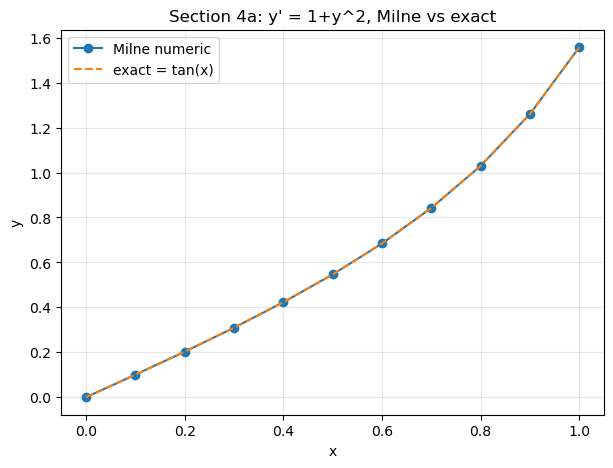

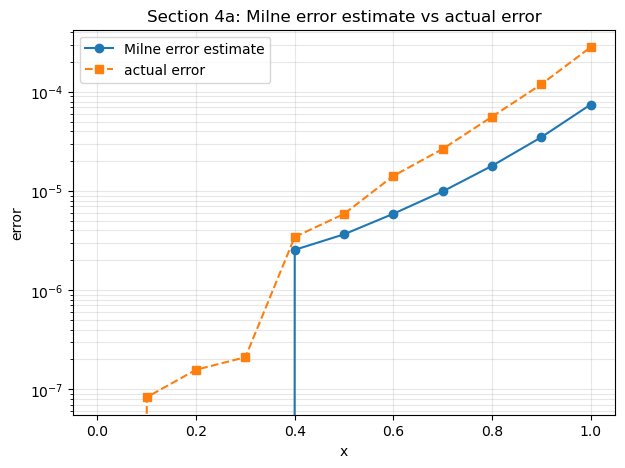

Q4b milne xplusy
 x_n  y_predicted  y_corrected  corrector_iters  Milne_error_estimate  actual_error
   0          NaN            1                0                     0             0
 0.1          NaN    1.1103417                0                     0 1.6948463e-07
 0.2          NaN    1.2428051                0                     0 3.7461895e-07
 0.3          NaN     1.399717                0                     0 6.2102693e-07
 0.4    1.5836416    1.5836492                5        -2.6191878e-07 1.7565377e-07
 0.5    1.7974339    1.7974422                5        -2.8618238e-07 3.4497327e-07
 0.6    2.0442277    2.0442377                5        -3.4648491e-07 1.4384615e-07
 0.7    2.3274946    2.3275055                5        -3.7678245e-07 7.0153257e-08
 0.8    2.6510702    2.6510825                5        -4.2235041e-07 6.2659452e-07
 0.9    3.0191935    3.0192069                5        -4.6102268e-07 6.7327998e-07
   1      3.43655     3.436565                5        -5.1

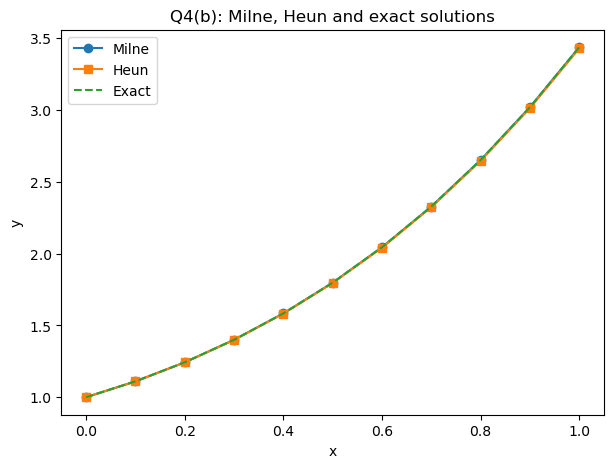

Q4b milne vs heun
 x_n   Milne_error    Heun_error
   0             0             0
 0.1 1.6948463e-07 0.00034183615
 0.2 3.7461895e-07 0.00075551632
 0.3 6.2102693e-07  0.0012523652
 0.4 1.7565377e-07   0.001845294
 0.5 3.4497327e-07  0.0025490095
 0.6 1.4384615e-07  0.0033802481
 0.7 7.0153257e-08  0.0043580402
 0.8 6.2659452e-07  0.0055040079
 0.9 6.7327998e-07   0.006842699
   1 1.3283688e-06  0.0084019637


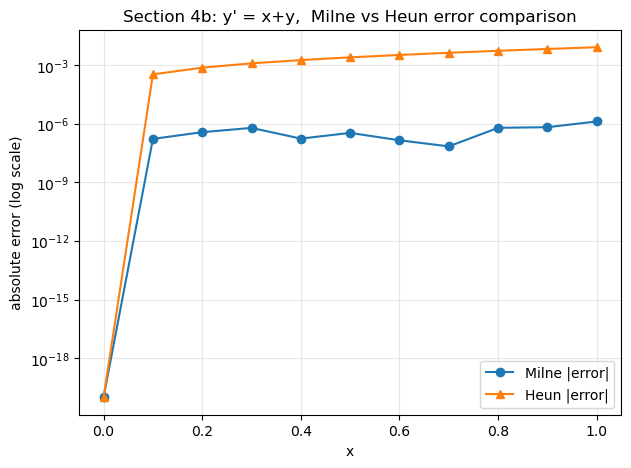

Max |Milne error| = 1.328e-06, max |Heun error| = 8.402e-03


In [ ]:
# Q4

print_r, show_plt = save_op(4)


def print_table(frame):
    print_r(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))

def milne_pc(f, y0, x0, xf, h, tol=1e-10, max_iter=500):
    y0 = np.atleast_1d(np.asarray(y0, dtype=float))
    n_eq = y0.size
    N = int(round((xf - x0)/h))

    x = x0 + h * np.arange(N + 1)
    Y = np.zeros((N + 1, n_eq))
    Ypred = np.full((N + 1, n_eq), np.nan)
    n_iters = np.zeros(N + 1, dtype=int)
    err_est = np.zeros((N + 1, n_eq))

    _, Y_start = rk4_system(f, y0, x0, x0 + 3 * h, h)
    Y[0:4] = Y_start
    F = [f(x[i], Y[i]) for i in range(4)]

    for n in range(3, N):
        f_nm2, f_nm1, f_n = F[n - 2], F[n - 1], F[n]

        y_pred = Y[n - 3] + (4 * h/3) * (2 * f_n - f_nm1 + 2 * f_nm2)
        Ypred[n + 1] = y_pred

        y_corr = y_pred.copy()
        k_used = 0
        for k in range(1, max_iter + 1):
            f_np1 = f(x[n + 1], y_corr)
            y_new = Y[n - 1] + (h/3) * (f_nm1 + 4 * f_n + f_np1)
            k_used = k
            if np.max(np.abs(y_new - y_corr)) < tol:
                y_corr = y_new
                break
            y_corr = y_new

        Y[n + 1] = y_corr
        n_iters[n + 1] = k_used
        err_est[n + 1] = -(1.0/29.0) * (Y[n + 1] - Ypred[n + 1])
        F.append(f(x[n + 1], Y[n + 1]))

    return {"x": x, "Y": Y, "Ypred": Ypred, "n_iters": n_iters, "err_est": err_est}


def _milne_table(f, y0, x0, xf, h, exact_fn, comp=0):
    res = milne_pc(f, y0, x0, xf, h)
    x, Y, Ypred, n_iters, err_est = (res["x"], res["Y"], res["Ypred"],
                                      res["n_iters"], res["err_est"])
    ye = exact_fn(x)
    actual_err = np.abs(Y[:, comp] - ye)
    df = pd.DataFrame({
        "x_n": x,
        "y_predicted": Ypred[:, comp],
        "y_corrected": Y[:, comp],
        "corrector_iters": n_iters,
        "Milne_error_estimate": err_est[:, comp],
        "actual_error": actual_err,
    })
    return x, Y, ye, actual_err, err_est, df

def f_a(x, y):
    return np.array([1.0 + y[0] ** 2])

x, Y, ye, actual_err, err_est, df = _milne_table(
    f_a, [0.0], 0.0, 1.0, 0.1, np.tan)
print_r("Q4a milne tan")
print_table(df)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, Y[:, 0], "o-", label="Milne numeric")
ax.plot(x, ye, "--", label="exact = tan(x)")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Section 4a: y' = 1+y^2, Milne vs exact")
ax.legend(); ax.grid(True, alpha=0.3)
show_plt()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, np.abs(err_est[:, 0]), "o-", label="Milne error estimate")
ax.plot(x, actual_err, "s--", label="actual error")
ax.set_xlabel("x"); ax.set_ylabel("error")
ax.set_yscale("log")
ax.set_title("Section 4a: Milne error estimate vs actual error")
ax.legend(); ax.grid(True, alpha=0.3, which="both")
show_plt()

def f_b(x, y):
    return np.array([x + y[0]])

def exact_b(x):
    return 2 * np.exp(x) - x - 1

x, Y, ye, actual_err, err_est, df = _milne_table(
    f_b, [1.0], 0.0, 1.0, 0.1, exact_b)
print_r("Q4b milne xplusy")
print_table(df)

x_h, Y_h = heun_system(f_b, [1.0], 0.0, 1.0, 0.1)
err_heun = np.abs(Y_h[:, 0] - exact_b(x_h))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, Y[:, 0], "o-", label="Milne")
ax.plot(x_h, Y_h[:, 0], "s-", label="Heun")
ax.plot(x, ye, "--", label="Exact")
ax.set(xlabel="x", ylabel="y", title="Q4(b): Milne, Heun and exact solutions")
ax.legend()
show_plt()

df_cmp = pd.DataFrame({
    "x_n": x,
    "Milne_error": actual_err,
    "Heun_error": err_heun,
})
print_r("Q4b milne vs heun")
print_table(df_cmp)

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(x, actual_err + 1e-20, "o-", label="Milne |error|")
ax.semilogy(x_h, err_heun + 1e-20, "^-", label="Heun |error|")
ax.set_xlabel("x"); ax.set_ylabel("absolute error (log scale)")
ax.set_title("Section 4b: y' = x+y,  Milne vs Heun error comparison")
ax.legend(); ax.grid(True, alpha=0.3, which="both")
show_plt()

print_r(f"Max |Milne error| = {actual_err.max():.3e}, "
      f"max |Heun error| = {err_heun.max():.3e}")

5(a), h = 0.25
   x      Euler  Backward Euler       Heun   Midpoint        RK4      Milne      exact
   0        0.5             0.5        0.5        0.5        0.5        0.5        0.5
0.25     0.5625      0.56155281 0.56201172 0.56225586 0.56217637 0.56217637  0.5621765
 0.5 0.62402344      0.62042714 0.62212295 0.62259261 0.62245905 0.62245905 0.62245933
0.75 0.68267798      0.67524908 0.67866835 0.67931935 0.67917823 0.67917823  0.6791787
   1 0.73683517      0.72508344 0.73038099 0.73115363 0.73105786 0.73105874 0.73105858


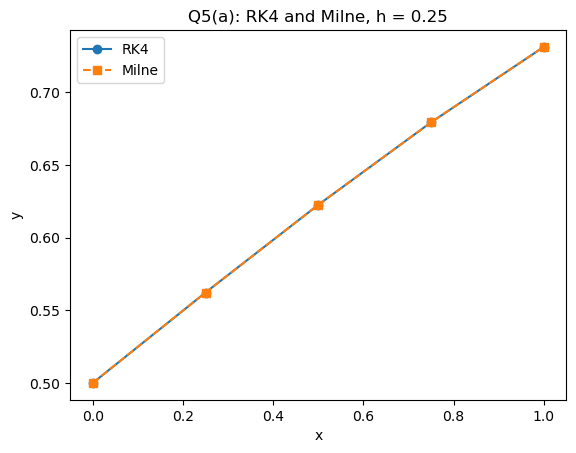

Euler: maximum absolute error = 5.77659413e-03
Backward Euler: maximum absolute error = 5.97513844e-03
Heun: maximum absolute error = 6.77593277e-04
Midpoint: maximum absolute error = 1.40651631e-04
RK4: maximum absolute error = 7.18022610e-07
Milne: maximum absolute error = 4.71692422e-07


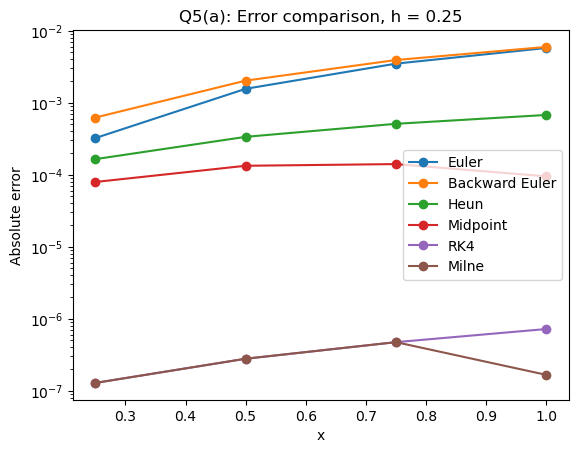

5(a), h = 0.125
    x      Euler  Backward Euler       Heun   Midpoint        RK4      Milne      exact
    0        0.5             0.5        0.5        0.5        0.5        0.5        0.5
0.125    0.53125      0.53112887 0.53118896 0.53121948 0.53120937 0.53120937 0.53120937
 0.25 0.56237793      0.56189992 0.56213545 0.56219589 0.56217649 0.56217649  0.5621765
0.375 0.59314155      0.59208986 0.59260472 0.59269358 0.59266659 0.59266659  0.5926666
  0.5 0.62330714      0.62149474 0.62237651 0.62249147 0.62245931 0.62245938 0.62245933
0.625 0.65265655      0.64993468 0.65125117 0.65138922 0.65135484  0.6513549 0.65135486
 0.75 0.68099355      0.67725717 0.67905442 0.67921205 0.67917867 0.67917878  0.6791787
0.875 0.70814872      0.70333884 0.70564074 0.70581414 0.70578499 0.70578506 0.70578503
    1 0.73398298      0.72808594 0.73089519 0.73108042 0.73105853 0.73105865 0.73105858


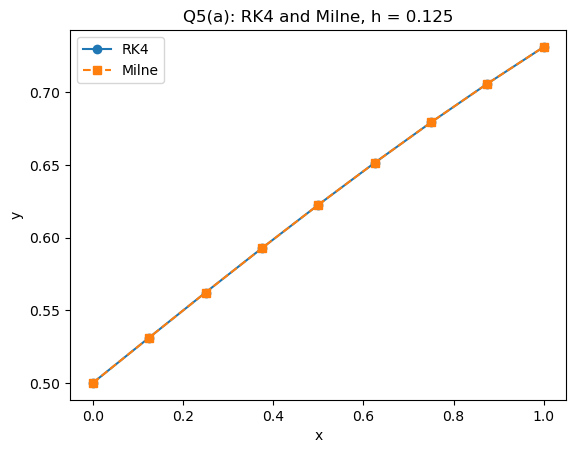

Euler: maximum absolute error = 2.92440323e-03
Backward Euler: maximum absolute error = 2.97264239e-03
Heun: maximum absolute error = 1.63388858e-04
Midpoint: maximum absolute error = 3.43566405e-05
RK4: maximum absolute error = 4.51193984e-08
Milne: maximum absolute error = 7.87724989e-08


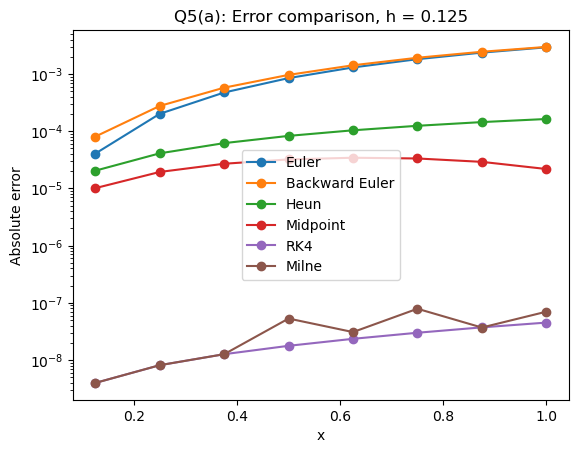

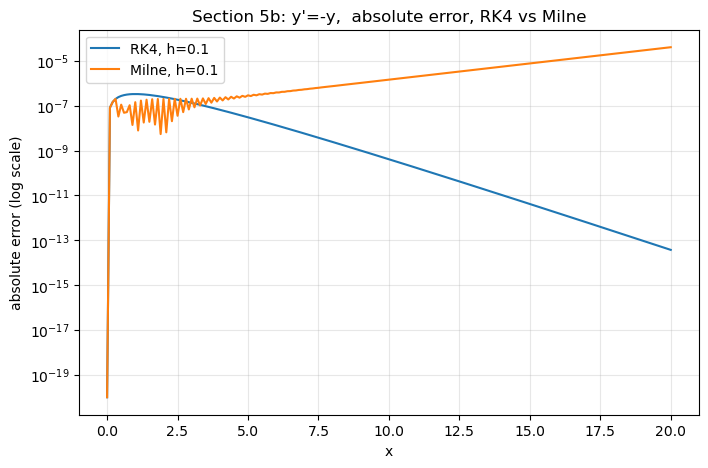

h=0.1  max |error| RK4=3.332e-07, Milne=4.083e-05 (at x=20: 4.083e-05)
Milne h=0.1: max |error| = 4.083e-05 (error at x=20: 4.083e-05)
Milne h=0.05: max |error| = 1.481e-06 (error at x=20: 1.481e-06)
Milne h=0.025: max |error| = 4.648e-08 (error at x=20: 4.648e-08)


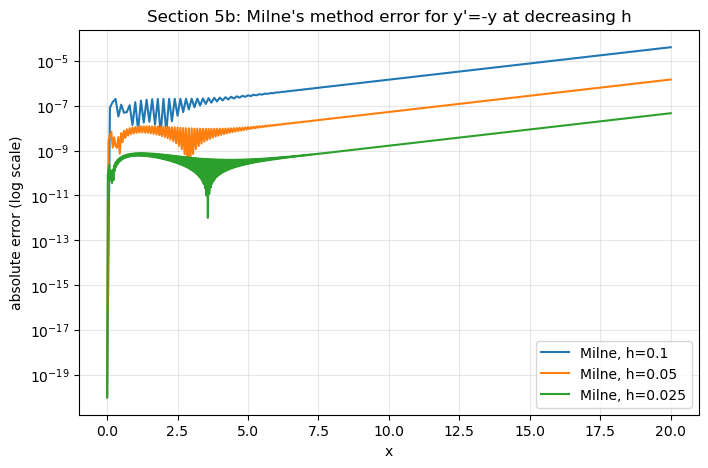

Milne parasitic root magnitude by step size:
0.1 1.033869625891401
0.05 1.0168031933415687
0.025 1.0083677632150922


In [ ]:
# Q5

print_r, show_plt = save_op(5)

def euler_method(f, x0, y0, x_end, h):
    N = int(round((x_end - x0)/h))
    x = x0 + h * np.arange(N + 1)
    y = np.zeros(N + 1)
    y[0] = y0
    for n in range(N):
        y[n+1] = y[n] + h * f(x[n], y[n])
    return x, y


def backward_euler(f, x0, y0, x_end, h):
    N = int(round((x_end - x0)/h))
    x = x0 + h * np.arange(N + 1)
    y = np.zeros(N + 1)
    y[0] = y0

    for n in range(N):
        a = h
        b = 1 - h
        c = -y[n]
        disc = b**2 - 4*a*c
        y[n+1] = (-b + np.sqrt(disc))/(2*a)

    return x, y


def modified_euler(f, x0, y0, x_end, h):
    N = int(round((x_end - x0)/h))
    x = x0 + h * np.arange(N + 1)
    y = np.zeros(N + 1)
    y[0] = y0

    for n in range(N):
        k1 = f(x[n], y[n])
        y_mid = y[n] + h/2*k1
        k2 = f(x[n] + h/2, y_mid)
        y[n+1] = y[n] + h*k2

    return x, y

def f(x, y):
    return y * (1 - y)

for h in (0.25, 0.125):
    x, y_euler = euler_method(f, 0, 0.5, 1, h)
    _, y_backward = backward_euler(f, 0, 0.5, 1, h)
    _, y_heun = heun_system(f, [0.5], 0, 1, h)
    _, y_midpoint = modified_euler(f, 0, 0.5, 1, h)
    _, y_rk4 = rk4_system(f, [0.5], 0, 1, h)
    y_milne = milne_pc(f, [0.5], 0, 1, h)["Y"][:, 0]
    solutions = {
        "Euler": y_euler,
        "Backward Euler": y_backward,
        "Heun": y_heun[:, 0],
        "Midpoint": y_midpoint,
        "RK4": y_rk4[:, 0],
        "Milne": y_milne,
    }
    exact = 1/(1 + np.exp(-x))

    print_r(f"5(a), h = {h}")
    print_table(pd.DataFrame({"x": x, **solutions, "exact": exact}))

    fig, ax = plt.subplots()
    ax.plot(x, solutions["RK4"], "o-", label="RK4")
    ax.plot(x, solutions["Milne"], "s--", label="Milne")
    ax.set(xlabel="x", ylabel="y", title=f"Q5(a): RK4 and Milne, h = {h}")
    ax.legend()
    show_plt()

    fig, ax = plt.subplots()
    for name, y in solutions.items():
        error = np.abs(y - exact)
        print_r(f"{name}: maximum absolute error = {error.max():.8e}")
        ax.semilogy(x[1:], error[1:], "o-", label=name)
    ax.set(xlabel="x", ylabel="Absolute error", title=f"Q5(a): Error comparison, h = {h}")
    ax.legend()
    show_plt()


# 5(b): y' = -y, y(0)=1, 0<=x<=20, RK4 vs Milne (h=0.1, then 0.05, 0.025)
def f_b(x, y):
    return np.array([-y[0]])

def exact_b(x):
    return np.exp(-x)

h = 0.1
x_rk4, Y_rk4 = rk4_system(f_b, [1.0], 0.0, 20.0, h)
milne_res = milne_pc(f_b, [1.0], 0.0, 20.0, h)
x_m, Y_m = milne_res["x"], milne_res["Y"]

err_rk4 = np.abs(Y_rk4[:, 0] - exact_b(x_rk4))
err_milne = np.abs(Y_m[:, 0] - exact_b(x_m))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(x_rk4, err_rk4 + 1e-20, label="RK4, h=0.1")
ax.semilogy(x_m, err_milne + 1e-20, label="Milne, h=0.1")
ax.set_xlabel("x"); ax.set_ylabel("absolute error (log scale)")
ax.set_title("Section 5b: y'=-y,  absolute error, RK4 vs Milne")
ax.legend(); ax.grid(True, alpha=0.3, which="both")
show_plt()

print_r(f"h=0.1  max |error| RK4={err_rk4.max():.3e}, "
      f"Milne={err_milne.max():.3e} (at x=20: {err_milne[-1]:.3e})")

fig, ax = plt.subplots(figsize=(8, 5))
for h2 in (0.1, 0.05, 0.025):
    milne_res_h = milne_pc(f_b, [1.0], 0.0, 20.0, h2)
    x_mh, Y_mh = milne_res_h["x"], milne_res_h["Y"]
    err_mh = np.abs(Y_mh[:, 0] - exact_b(x_mh))
    ax.semilogy(x_mh, err_mh + 1e-20, label=f"Milne, h={h2}")
    print_r(f"Milne h={h2}: max |error| = {err_mh.max():.3e} "
          f"(error at x=20: {err_mh[-1]:.3e})")
ax.set_xlabel("x"); ax.set_ylabel("absolute error (log scale)")
ax.set_title("Section 5b: Milne's method error for y'=-y at decreasing h")
ax.legend(); ax.grid(True, alpha=0.3, which="both")
show_plt()
# For y'=-y, the converged corrector has roots of
# (1+h/3)*z**2 + (4*h/3)*z - (1-h/3) = 0.
# Its negative root has magnitude greater than one for every h > 0.
print_r("Milne parasitic root magnitude by step size:")
for h in (0.1, 0.05, 0.025):
    a = 1 + h/3
    b = 4 * h/3
    c = -(1 - h/3)
    root = (-b - np.sqrt(b*b - 4*a*c))/(2*a)
    print_r(h, abs(root))